In [1]:
#import all of the important libraries and such
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import linregress
import math
import seaborn as sns

#list the name of the csv file of interest
infile = 'Raw_traces/CreWT_10pN_traces_renumbered.csv' #name of the file that contains MSD vs time
data = pd.read_csv(infile, sep=',',skiprows=1, header=None, names=['trackindex', 't_pix','p_pix', 't_sec', 'p_mic', 'counts'])

df = pd.DataFrame(data) #creates a new dataframe named df based on the infile

print(df) #check to make sure everything is correct

#add in a nickname for the input file
inputfile = 'CreWT_10pN'

       trackindex  t_pix      p_pix      t_sec     p_mic  counts
0               0    0.0  57.625000   0.000000  5.762500    40.0
1               0    1.0  58.772727   0.033894  5.877273    25.0
2               0    2.0  59.500000   0.067789  5.950000    24.0
3               0    3.0  58.571429   0.101683  5.857143    28.0
4               0    4.0  58.000000   0.135578  5.800000    36.0
...           ...    ...        ...        ...       ...     ...
34765         307  900.0  53.111111  64.604160  5.311111   180.0
34766         307  901.0  51.321608  64.675942  5.132161   199.0
34767         307  902.0  51.110092  64.747725  5.111009   218.0
34768         307  903.0  52.011173  64.819507  5.201117   179.0
34769         307  904.0  51.132075  64.891290  5.113208   212.0

[34770 rows x 6 columns]


In [25]:
### calculate the MSD for all trajectories to determine D-coeff using a smoothening function ###
df['MSD(n)'] = 0
df['n'] = 0
df['ndt'] = 0
df['ln(MSD)'] = 0
df['ln(ndt)'] = 0
df['tau'] = 0

#Creates a new df to store results from when I fit the diff coef and alpha value
results = pd.DataFrame(columns=['track_number', 'D(um^2 sec^-1)', 'D_R^2', 'alpha', 'a_R^2'])
results.reset_index(drop=True, inplace=True) #this resets the index for each group

df_MSD = pd.DataFrame() #creates a new dataframe to store the new MSD values for each trace

grouped = df.groupby('trackindex')#groups values in the infile by trackindex
df.reset_index(drop=True, inplace=True) #this resets the index for each group

for track_id, group in grouped: #iterate based on the track id for each group
    group.reset_index(drop=True, inplace=True) # resets the index so that I can update the MSD and ndt iteratively
    indexn = group['trackindex']
    N = len(group) #value for total number of steps in the trace
    tau = group['t_sec'].max()-group['t_sec'].iloc[0] #calculate length of trace
    group['p_roll'] = group['p_mic'].rolling(window=3,center=True).mean() #smoothen the trace
    group['p_roll'].iloc[0] = group['p_mic'].iloc[0] 
    group = group[:-1] #remove zero point
    
    N = len(group) #value for total number of steps in the trace
    if N > 25:
        
        dt = group['t_sec'].iloc[1] - group['t_sec'].iloc[0]
        dt = float(dt)
        for n in range(1,30): #set a counter for the value of n from 1 to 30 (ndt > 1 sec)

            sum_sqdif = 0 #sets the sum of squared differences = 0
        
            for i in range(2,N-n): #for loop to calculate MSD for different 
            
                sqdif = (group.iloc[i+n]['p_roll'] - group.iloc[i]['p_roll'])**2 #calculates the squared difference between two points

                sum_sqdif += sqdif #sums each of the squared differences
            
                MSDn = sum_sqdif/(N-n) #calculates the MSD for the given n value
            
            ndt = int(n)*dt #total time of the steps ndt

            group.loc[n-1, 'MSD(n)'] = MSDn #save MSD values to df, taking into account the indexed value of n

            group.loc[n-1, 'n'] = n #save n values to df
        
            group.loc[n-1, 'ndt'] = ndt # time for fitting MSD vs time
        
            group.loc[n-1, 'ln(MSD)'] = np.log(MSDn) #saves the log of the MSD
    
            group.loc[n-1, 'ln(ndt)'] = np.log(ndt) # saves the log of ndt
    
    
        #fit points 3-13 to a linear function to determine Dapp (no alpha dependence)
        y = group['MSD(n)'][2:12]
        x = group['ndt'][2:12]
    
        slope, intercept, r_value, p_value, std_err = linregress(x, y) #calculate the slope
        D_app = slope/2 #calculate the apparent diff coefficient
        D_corr = np.corrcoef(x, y)[0,1] #determine correlation coeff
    
        #to determine alpha value, the same is done with the log-log of MSD(n) vs ndt
        ya = group['ln(MSD)'][3:23] 
        xa = group['ln(ndt)'][3:23]
    
        slope, intercept, r_value, p_value, std_err = linregress(xa, ya)
        alpha = slope
        D = (np.exp(intercept))/2 # calculate diff coefficient
        a_corr = np.corrcoef(x, y)[0,1]
        #save the data for traces of sufficient length with appropriate correlations
        if len(group)>20:
            if a_corr > 0.1:
                indexn = indexn[1]
                results.loc[indexn,'track_number'] = indexn 
                results.loc[indexn,'D(um^2 sec^-1)'] = D
                results.loc[indexn,'D_R^2'] = D_corr
                results.loc[indexn,'alpha'] = alpha
                results.loc[indexn,'a_R^2'] = a_corr
                results.loc[indexn,'tau'] = tau
        df_MSD = pd.concat([df_MSD, group], ignore_index=True) #combines all of the traces back together into 1 df
print(results)
results = results.dropna(subset=['alpha'])
#save the results to a csv file for alternative analysis
#df_MSD.to_csv('processed_traces/CreWT_10pN_traces_MSD_3proll.csv') #input csv with additional columns for MSD
#results.to_csv('processed_traces/CreWT_10pN_track_fitvalues_3proll.csv') # results of fitting, 1 row per trace

/Users/montgomery.1158/opt/anaconda3/lib/python3.8/site-packages/pandas/core/indexing.py:1637: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)
/Users/montgomery.1158/opt/anaconda3/lib/python3.8/site-packages/pandas/core/indexing.py:1720: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value, pi)


    track_number D(um^2 sec^-1)     D_R^2     alpha     a_R^2        tau
0              0       0.054777  0.998502   1.16591  0.998502   7.863501
1              1        0.01528   0.98941  1.077953   0.98941   2.609869
2              2       0.010023  0.963752  0.822075  0.963752   1.084621
3              3       0.050345  0.991152   1.37081  0.991152   2.643763
4              4       0.043909  0.999892   0.91566  0.999892   4.033433
..           ...            ...       ...       ...       ...        ...
303          303       0.037589  0.994177  1.495075  0.994177   3.373773
304          304       0.038236   0.99935  0.908151   0.99935  11.413402
305          305       0.018507  0.999516  1.083457  0.999516   6.532198
306          306       0.179013  0.997849  1.503852  0.997849   7.824281
307          307       0.008623  0.997817  1.028889  0.997817  17.155994

[229 rows x 6 columns]


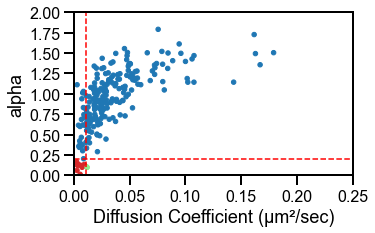

percent mobile: 0.8513513513513513


In [26]:
###Mobile fraction###
### Correlate alpha and D to characterize the distrobution and with cutoffs for nucleosome core particles##
plt.figure(figsize=(5,3))
results = results[results['alpha'] > 0]
results2 = results[results['tau'] > 1]

# Define threshold values
diffusion_threshold = 0.011
alpha_threshold = 0.2
# Color points based on threshold values
colors = []
for index, row in results2.iterrows():
    if row['D(um^2 sec^-1)'] > diffusion_threshold and row['alpha'] > alpha_threshold:
        colors.append('tab:blue')
    elif row['D(um^2 sec^-1)'] <= diffusion_threshold and row['alpha'] <= alpha_threshold:
        colors.append('tab:red')
    elif row['D(um^2 sec^-1)'] > diffusion_threshold and row['alpha'] <= alpha_threshold:
        colors.append('lightgreen')
    elif row['D(um^2 sec^-1)'] <= diffusion_threshold and row['alpha'] > alpha_threshold:
        colors.append('tab:blue')
plt.scatter(results2['D(um^2 sec^-1)'], results2['alpha'], c=colors, s=20)
plt.xlabel('D coef')
plt.ylabel('alpha')
plt.xlim(0,.25)
plt.ylim(0,2)
plt.axhline(y=0.2, color='r', linestyle='--')
plt.axvline(x=diffusion_threshold, color='r', linestyle='--')
ax = plt.gca()  # Get current axes
ax.spines['top'].set_linewidth(2)    # Top border
ax.spines['right'].set_linewidth(2)  # Right border
ax.spines['bottom'].set_linewidth(2) # Bottom border
ax.spines['left'].set_linewidth(2)   # Left border
plt.xticks(fontsize=16, fontfamily='arial')
plt.yticks(fontsize=16, fontfamily='arial')
plt.ylabel('alpha', fontsize=18, fontfamily='arial')
plt.xlabel('Diffusion Coefficient (μm\u00b2/sec)', fontsize=18, fontfamily='arial')
plt.tick_params(axis='y', which='both', length=10, width=2)
plt.tick_params(axis='x', which='both', length=10, width=2)
#plt.savefig("Figure_output/CreWT_scanning_v_alpha.svg", dpi = 600, format = 'svg')
plt.show()

#calculate mobile fraction#
results_mobile = results2[results2['alpha'] >= alpha_threshold]
results_mobile = results_mobile[results_mobile['D(um^2 sec^-1)'] >= diffusion_threshold]

print("percent mobile:", len(results_mobile)/len(results2))

[0.03263745 1.02126149] [6.50593915e-05 4.38057492e-03]


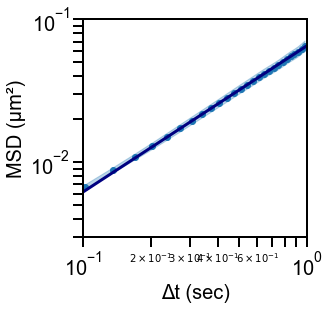

In [32]:
##estimating the anomolous diffusion exponent##
### Average MSD vs time plot for traces that have the same dt (linetime, time resolution)
plt.figure(figsize = (4,4))
def diffusion(dt,D,a):
    return 2*D*(dt**a)

WT_dt = 0.0339 #set this to the desired value
sub_MSD = df_MSD[df_MSD['ndt']<1.1]
single_dt = pd.DataFrame()
grouped = sub_MSD.groupby('trackindex')
for track_id, group in grouped: #iterate based on the track id for each group
    group.reset_index(drop=True, inplace=True) # resets the index so that I can update the MSD and ndt iteratively
    indexn = group['trackindex']
    N = len(group) #value for total number of steps in the trace
    dt = group['t_sec'].iloc[2] - group['t_sec'].iloc[1]
    dt = dt.round(4)
    group['dt'] = dt
    group['ndt'] = (group['n']*group['dt'])
    if group['dt'].iloc[0] == WT_dt:
        single_dt = pd.concat([single_dt, group], ignore_index=True)
mean_msd = single_dt.groupby('ndt')['MSD(n)'].mean()
sem_msd = single_dt.groupby('ndt')['MSD(n)'].sem()
result_df = pd.DataFrame({
    'ndt': mean_msd.index,
    'mean': mean_msd.values,
    'error': sem_msd.values})
plt.plot(result_df['ndt'],result_df['mean'],'o',color='tab:blue')
plt.fill_between(result_df['ndt'], result_df['mean'] - result_df['error'], result_df['mean'] + result_df['error'], color='tab:blue', alpha=0.3, label='Error')
result_df = result_df[result_df['ndt'] > 0.11]

popt,pcov = curve_fit(diffusion,result_df['ndt'],result_df['mean'])
perr = np.sqrt(np.diag(pcov))
print(popt,perr)
x = np.linspace(0,1,100)
plt.plot(x,diffusion(x,*popt),color='navy',linewidth=3)

plt.xlim(0.10,1)
plt.ylim(0.003,0.1)
plt.xscale('log')
plt.yscale('log')
ax = plt.gca()  # Get current axes
ax.spines['top'].set_linewidth(2)    # Top border
ax.spines['right'].set_linewidth(2)  # Right border
ax.spines['bottom'].set_linewidth(2) # Bottom border
ax.spines['left'].set_linewidth(2)   # Left border
plt.xticks(fontsize=20, fontfamily='arial')
plt.yticks(fontsize=20, fontfamily='arial')
plt.ylabel('MSD (μm\u00b2)', fontsize=20, fontfamily='arial')
plt.xlabel('Δt (sec)', fontsize=20, fontfamily='arial')
plt.tick_params(axis='y', which='both', length=10, width=2)
plt.tick_params(axis='x', which='both', length=10, width=2)
#plt.savefig("Figure_output/Cre_avgMSD_loglog_int.svg", dpi = 600, format = 'svg')
plt.show()

5.628043267536643 0.24255719802214012
5.52758167644195  +/-  0.6778767730459616


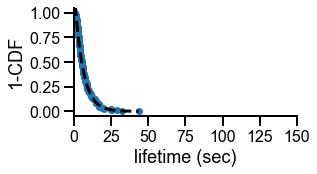

In [38]:
### Generate a 1-CDF plot fit to a single decay for WT Cre lifetimes on lambda DNA ###
def exp_decay(x, k,z):
    return np.exp(-k * x+z)
def one_cdf(data):
    sorted_data = np.sort(data)
    cdf = np.arange(1, len(data) + 1) / len(data)
    one_cdf = 1 - cdf
    return sorted_data, one_cdf
plt.figure(figsize=(4,2))
WT = one_cdf(results['tau'])
plt.plot(WT[0],WT[1],'o',color='tab:blue')
popt,pcov = curve_fit(exp_decay,WT[0],WT[1])
print(1/popt[0],popt[1])
plt.plot(WT[0],exp_decay(WT[0],*popt),'--',color='black',linewidth=3)
p0 = popt
data = results['tau']
n_iterations = 1000
bootstrap_params = np.zeros((n_iterations, len(popt)))
for i in range(n_iterations):
    sample = data.sample(frac=0.368, replace=True).values
    x_data, y_data = one_cdf(sample)
    popt_sample, _ = curve_fit(exp_decay, x_data, y_data,p0=p0)
    bootstrap_params[i] = popt_sample
bootstrap_means = np.mean(bootstrap_params, axis=0)
bootstrap_stds = np.std(bootstrap_params, axis=0)
print(1/bootstrap_means[0]," +/- ",1/bootstrap_means[0]*(bootstrap_stds[0]/bootstrap_means[0]))
#Figure stuff##
ax = plt.gca()  # Get current axes
ax.spines['top'].set_linewidth(0)    # Top border
ax.spines['right'].set_linewidth(0)  # Right border
ax.spines['bottom'].set_linewidth(2) # Bottom border
ax.spines['left'].set_linewidth(2)   # Left border
plt.xlim(0,150)
plt.ylim(-0.05,1.05)
#plt.yscale('log')
plt.locator_params(axis='y', nbins=5)  # Adjust the number of ticks
plt.xticks(fontsize=16, fontfamily='arial')
plt.yticks(fontsize=16, fontfamily='arial')
plt.ylabel('1-CDF', fontsize=18, fontfamily='arial')
plt.xlabel('lifetime (sec)', fontsize=18, fontfamily='arial')
plt.tick_params(axis='y', which='both', length=10, width=2)
plt.tick_params(axis='x', which='both', length=10, width=2)
#plt.savefig("Figure_output/CreWT_lifetimes.svg", dpi = 600, format = 'svg')
plt.show()